# PCA from scratch: 167 countries in two dimensions

Principal Component Analysis implemented with nothing but NumPy array arithmetic: standardisation, the correlation matrix, a cyclic **Jacobi** eigenvalue solver, explained variance, loadings and scores. The result is checked against `np.linalg.eigh` and `sklearn.decomposition.PCA`.

The same algorithm runs live in the browser in [`pca_explorer.html`](pca_explorer.html).

## 1. Problem

Each country is described by 9 socio-economic indicators, so it is a point in $\mathbb{R}^9$. We cannot draw that. PCA finds the orthogonal directions along which the (standardised) data varies most, so that a 2D or 3D picture keeps as much of the structure as possible. Two questions drive the analysis:

1. How much of the total variance does each principal component explain?
2. Which indicators drive the first few components, and how do countries spread along them?

## 2. Data

`data/countries.csv` is the [Unsupervised Learning on Country Data](https://www.kaggle.com/datasets/rohan0301/unsupervised-learning-on-country-data) table from Kaggle: 167 countries × 9 indicators (child mortality, exports, health spending, imports, income, inflation, life expectancy, fertility, GDP per capita). A `region` column was added for colouring only; it is not used in the PCA.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/countries.csv")
VARS = ["child_mort", "exports", "health", "imports", "income", "inflation", "life_expec", "total_fer", "gdpp"]
X = df[VARS].to_numpy(dtype=float)
n, p = X.shape
print(f"{n} countries x {p} indicators, missing values: {int(np.isnan(X).sum())}")
df.head()

167 countries x 9 indicators, missing values: 0


,country,region,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,Asia,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,Europe,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,Africa,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,Africa,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,Americas,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


In [2]:
summary = pd.DataFrame({"mean": X.mean(axis=0), "sample std": X.std(axis=0, ddof=1)}, index=VARS)
summary.round(3)

,mean,sample std
child_mort,38.270,40.329
exports,41.109,27.412
health,6.816,2.747
imports,46.890,24.210
income,17144.689,19278.068
inflation,7.782,10.571
life_expec,70.556,8.893
total_fer,2.948,1.514
gdpp,12964.156,18328.705


The standard deviations span four orders of magnitude (income and GDP in dollars versus fertility in children per woman), so the raw covariance matrix would be dominated by two columns. That is why PCA here is done on standardised data.

## 3. Method

**Standardise** each column to zero mean and unit sample variance:

$$\tilde{X}_{ij} = \frac{X_{ij} - \hat{\mu}_j}{\hat{s}_j}$$

**Correlation matrix.** On standardised data the covariance matrix *is* the correlation matrix:

$$R = \frac{1}{n-1}\tilde{X}^\top \tilde{X}, \qquad \operatorname{trace}(R) = p = 9$$

**Eigendecomposition.** $R = V \Lambda V^\top$ with $V^\top V = I$. The eigenvalues $\lambda_1 \ge \dots \ge \lambda_p$ are the variances along the principal axes; the columns of $V$ are the axes (the *loadings*).

**Jacobi's method** computes this without any library call. For a symmetric matrix $A$, pick an off-diagonal entry $a_{qr}$ and build the plane rotation $J(q, r, \theta)$ that makes $(J^\top A J)_{qr} = 0$. Applying this to every pair $(q, r)$ in turn is one *sweep*; each sweep shrinks the off-diagonal Frobenius norm, and after a handful of sweeps $A$ is diagonal to machine precision. The product of all rotations is $V$, the diagonal is $\Lambda$.

**Explained variance** of component $k$ is $\lambda_k / \sum_j \lambda_j = \lambda_k / p$. **Scores** (coordinates of the countries on the new axes) are $Z = \tilde{X} V$; keeping the first two columns gives the 2D picture.

Eigenvector signs are arbitrary ($v$ and $-v$ span the same axis), so we fix them by making the largest-magnitude loading of each component positive.

In [3]:
def standardise(X):
    mu = X.mean(axis=0)
    sd = X.std(axis=0, ddof=1)
    return (X - mu) / sd, mu, sd


def correlation_matrix(Z):
    n = Z.shape[0]
    return Z.T @ Z / (n - 1)


def jacobi_eigen(A, tol=1e-12, max_sweeps=100):
    """Eigen-decomposition of a symmetric matrix by cyclic Jacobi rotations.
    Returns (eigenvalues, eigenvectors as columns, sweeps, rotations)."""
    A = A.copy()
    p = A.shape[0]
    V = np.eye(p)
    sweeps = rotations = 0

    def off_norm(M):
        off = M - np.diag(np.diag(M))
        return np.sqrt((off ** 2).sum())

    while off_norm(A) > tol and sweeps < max_sweeps:
        sweeps += 1
        for q in range(p - 1):
            for r in range(q + 1, p):
                if abs(A[q, r]) < 1e-300:
                    continue
                theta = (A[r, r] - A[q, q]) / (2 * A[q, r])
                t = np.sign(theta if theta != 0 else 1) / (abs(theta) + np.sqrt(theta ** 2 + 1))
                c = 1 / np.sqrt(t ** 2 + 1)
                s = t * c
                # A <- J^T A J, applied as column then row rotation
                Aq, Ar = A[:, q].copy(), A[:, r].copy()
                A[:, q], A[:, r] = c * Aq - s * Ar, s * Aq + c * Ar
                Aq, Ar = A[q, :].copy(), A[r, :].copy()
                A[q, :], A[r, :] = c * Aq - s * Ar, s * Aq + c * Ar
                # V <- V J
                Vq, Vr = V[:, q].copy(), V[:, r].copy()
                V[:, q], V[:, r] = c * Vq - s * Vr, s * Vq + c * Vr
                rotations += 1
    return np.diag(A).copy(), V, sweeps, rotations


def pca_from_scratch(X):
    Z, mu, sd = standardise(X)
    R = correlation_matrix(Z)
    values, vectors, sweeps, rotations = jacobi_eigen(R)
    order = np.argsort(values)[::-1]
    lam = values[order]
    V = vectors[:, order]
    # sign convention: largest |loading| in each column is positive
    signs = np.sign(V[np.abs(V).argmax(axis=0), np.arange(V.shape[1])])
    V = V * signs
    ratio = lam / lam.sum()
    scores = Z @ V
    return dict(Z=Z, mu=mu, sd=sd, R=R, lam=lam, V=V, ratio=ratio, cum=np.cumsum(ratio),
                scores=scores, sweeps=sweeps, rotations=rotations)


pca = pca_from_scratch(X)
print(f"Jacobi converged in {pca['sweeps']} sweeps ({pca['rotations']} rotations)")
print(f"sum of eigenvalues = {pca['lam'].sum():.6f} (should equal p = {p})")
print(f"max |V^T V - I|    = {np.abs(pca['V'].T @ pca['V'] - np.eye(p)).max():.2e}")
print(f"max |R V - V L|    = {np.abs(pca['R'] @ pca['V'] - pca['V'] * pca['lam']).max():.2e}")

Jacobi converged in 5 sweeps (180 rotations)
sum of eigenvalues = 9.000000 (should equal p = 9)
max |V^T V - I|    = 3.33e-15
max |R V - V L|    = 5.11e-15


## 4. Results

### Correlation matrix

In [4]:
R = pd.DataFrame(pca["R"], index=VARS, columns=VARS)
R.round(2)

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
child_mort,1.00,-0.32,-0.20,-0.13,-0.52,0.29,-0.89,0.85,-0.48
exports,-0.32,1.00,-0.11,0.74,0.52,-0.11,0.32,-0.32,0.42
health,-0.20,-0.11,1.00,0.10,0.13,-0.26,0.21,-0.20,0.35
imports,-0.13,0.74,0.10,1.00,0.12,-0.25,0.05,-0.16,0.12
income,-0.52,0.52,0.13,0.12,1.00,-0.15,0.61,-0.50,0.90
inflation,0.29,-0.11,-0.26,-0.25,-0.15,1.00,-0.24,0.32,-0.22
life_expec,-0.89,0.32,0.21,0.05,0.61,-0.24,1.00,-0.76,0.60
total_fer,0.85,-0.32,-0.20,-0.16,-0.50,0.32,-0.76,1.00,-0.45
gdpp,-0.48,0.42,0.35,0.12,0.90,-0.22,0.60,-0.45,1.00


In [5]:
pairs = [(VARS[i], VARS[j], pca["R"][i, j]) for i in range(p) for j in range(i + 1, p)]
pairs = sorted(pairs, key=lambda t: -abs(t[2]))[:5]
pd.DataFrame(pairs, columns=["variable A", "variable B", "r"]).round(3)

,variable A,variable B,r
0,income,gdpp,0.896
1,child_mort,life_expec,-0.887
2,child_mort,total_fer,0.848
3,life_expec,total_fer,-0.761
4,exports,imports,0.737


### Explained variance

In [6]:
ev = pd.DataFrame({
    "eigenvalue": pca["lam"],
    "explained variance %": pca["ratio"] * 100,
    "cumulative %": pca["cum"] * 100,
}, index=[f"PC{k+1}" for k in range(p)])
ev.round(3)

,eigenvalue,explained variance %,cumulative %
PC1,4.136,45.952,45.952
PC2,1.546,17.182,63.133
PC3,1.170,13.004,76.138
PC4,0.995,11.053,87.191
PC5,0.661,7.340,94.531
PC6,0.224,2.484,97.015
PC7,0.113,1.260,98.276
PC8,0.088,0.981,99.257
PC9,0.067,0.743,100.000


In [7]:
k80 = int(np.argmax(pca["cum"] >= 0.80)) + 1
n_kaiser = int((pca["lam"] > 1).sum())
print(f"Components needed for >= 80% of variance: {k80} (reaches {pca['cum'][k80-1]*100:.2f}%)")
print(f"Kaiser criterion (eigenvalue > 1): keep {n_kaiser} components; lambda_4 = {pca['lam'][3]:.3f} is borderline")
print(f"PC1 + PC2 retain {pca['cum'][1]*100:.2f}% of the variance; PC1-PC3 retain {pca['cum'][2]*100:.2f}%")

Components needed for >= 80% of variance: 4 (reaches 87.19%)
Kaiser criterion (eigenvalue > 1): keep 3 components; lambda_4 = 0.995 is borderline
PC1 + PC2 retain 63.13% of the variance; PC1-PC3 retain 76.14%


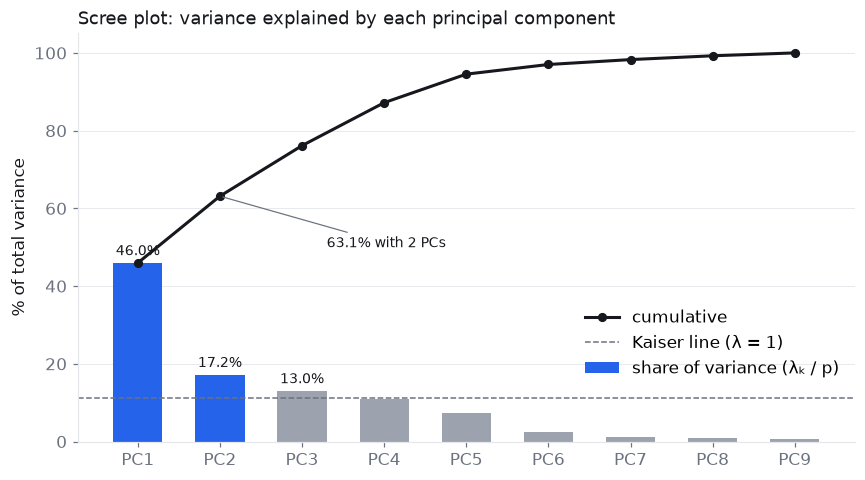

In [8]:
# Colour tokens used for every chart in this notebook (fixed order, never cycled)
INK, INK_MUTED, GRID = "#16181d", "#6b7280", "#e5e7eb"
PRIMARY, SECONDARY = "#2563eb", "#9ca3af"
REGION_COLORS = {"Africa": "#d97706", "Asia": "#2563eb", "Europe": "#059669", "Americas": "#dc2626", "Oceania": "#7c3aed"}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.labelcolor": INK, "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
})

ks = np.arange(1, p + 1)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(ks, pca["ratio"] * 100, width=0.6, color=[PRIMARY if k <= 2 else SECONDARY for k in ks], label="share of variance (λₖ / p)")
ax.plot(ks, pca["cum"] * 100, color=INK, lw=2, marker="o", ms=5, label="cumulative")
ax.axhline(100 / p, color=INK_MUTED, lw=1, ls="--", label="Kaiser line (λ = 1)")
for k in range(3):
    ax.annotate(f"{pca['ratio'][k]*100:.1f}%", (ks[k], pca["ratio"][k] * 100 + 2), ha="center", color=INK, fontsize=9)
ax.annotate(f"{pca['cum'][1]*100:.1f}% with 2 PCs", (2, pca["cum"][1] * 100), xytext=(3.3, 50), color=INK, fontsize=9,
            arrowprops=dict(arrowstyle="-", color=INK_MUTED, lw=0.8))
ax.set_xticks(ks, [f"PC{k}" for k in ks])
ax.set_ylabel("% of total variance")
ax.set_ylim(0, 105)
ax.set_title("Scree plot: variance explained by each principal component", loc="left", fontsize=12, color=INK)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 0.12))
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig("images/scree.png", bbox_inches="tight")
plt.show()

### Loadings: what each component measures

In [9]:
loadings = pd.DataFrame(pca["V"][:, :3], index=VARS, columns=["PC1", "PC2", "PC3"])
loadings.round(4)

,PC1,PC2,PC3
child_mort,-0.4195,0.1929,-0.0295
exports,0.2839,0.6132,0.1448
health,0.1508,-0.2431,-0.5966
imports,0.1615,0.6718,-0.2999
income,0.3984,0.0225,0.3015
inflation,-0.1932,-0.0084,0.6425
life_expec,0.4258,-0.2227,0.1139
total_fer,-0.4037,0.1552,0.0195
gdpp,0.3926,-0.0460,0.1230


In [10]:
for k, name in enumerate(["PC1", "PC2", "PC3"]):
    col = loadings[name].sort_values(key=np.abs, ascending=False)
    pos = ", ".join(f"{v} ({col[v]:+.3f})" for v in col.index if col[v] > 0)[:200]
    neg = ", ".join(f"{v} ({col[v]:+.3f})" for v in col.index if col[v] < 0)[:200]
    print(f"{name} ({pca['ratio'][k]*100:.1f}%)\n  positive: {pos}\n  negative: {neg}")

PC1 (46.0%)
  positive: life_expec (+0.426), income (+0.398), gdpp (+0.393), exports (+0.284), imports (+0.161), health (+0.151)
  negative: child_mort (-0.420), total_fer (-0.404), inflation (-0.193)
PC2 (17.2%)
  positive: imports (+0.672), exports (+0.613), child_mort (+0.193), total_fer (+0.155), income (+0.023)
  negative: health (-0.243), life_expec (-0.223), gdpp (-0.046), inflation (-0.008)
PC3 (13.0%)
  positive: inflation (+0.643), income (+0.302), exports (+0.145), gdpp (+0.123), life_expec (+0.114), total_fer (+0.020)
  negative: health (-0.597), imports (-0.300), child_mort (-0.030)


PC1 contrasts life expectancy, income and GDP per capita against child mortality and fertility: a **development** axis. PC2 is driven almost entirely by imports and exports: a **trade openness** axis, orthogonal to development by construction. PC3 separates inflation from health spending (% of GDP).

### Countries on the principal plane

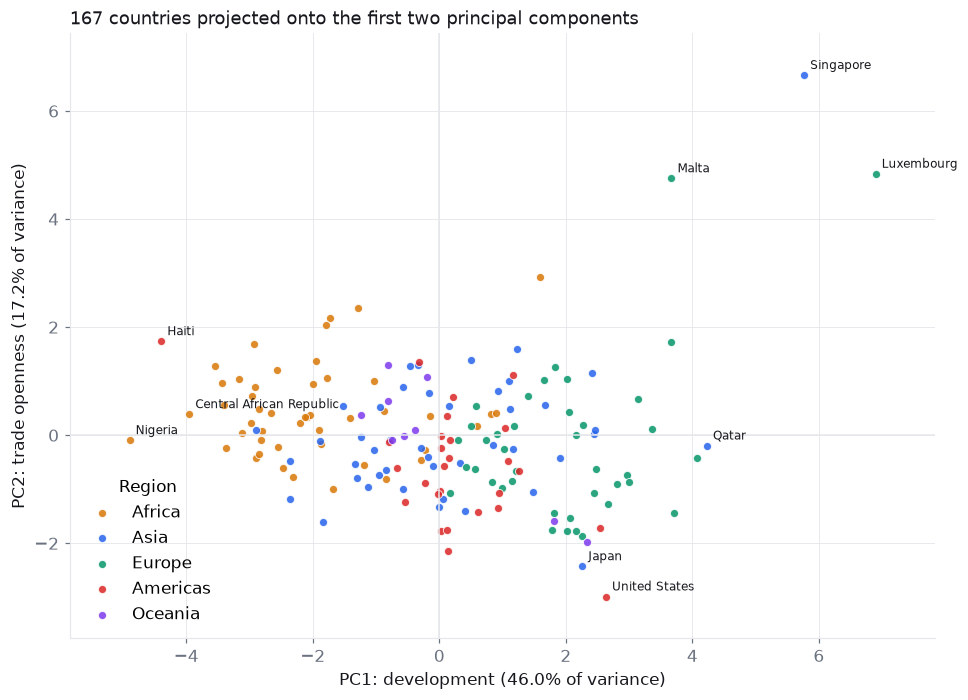

,country,region,PC1,PC2,PC3
91,Luxembourg,Europe,6.897,4.835,0.999
133,Singapore,Asia,5.766,6.662,0.652
123,Qatar,Asia,4.230,-0.195,3.633
145,Switzerland,Europe,4.076,-0.428,-0.261
114,Norway,Europe,3.710,-1.443,0.885


In [11]:
scores = pd.DataFrame(pca["scores"][:, :3], columns=["PC1", "PC2", "PC3"])
scores.insert(0, "country", df["country"])
scores.insert(1, "region", df["region"])

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.margins(x=0.08, y=0.08)
for region, color in REGION_COLORS.items():
    sub = scores[scores["region"] == region]
    ax.scatter(sub["PC1"], sub["PC2"], s=28, color=color, alpha=0.85, edgecolor="white", linewidth=0.6, label=region)
# label the extremes only
extremes = pd.concat([scores.nlargest(3, "PC1"), scores.nsmallest(3, "PC1"), scores.nlargest(3, "PC2"), scores.nsmallest(2, "PC2")])
for _, r in extremes.drop_duplicates("country").iterrows():
    ax.annotate(r["country"], (r["PC1"], r["PC2"]), xytext=(4, 4), textcoords="offset points", fontsize=8, color=INK)
ax.axhline(0, color=GRID, lw=1); ax.axvline(0, color=GRID, lw=1)
ax.set_xlabel(f"PC1: development ({pca['ratio'][0]*100:.1f}% of variance)")
ax.set_ylabel(f"PC2: trade openness ({pca['ratio'][1]*100:.1f}% of variance)")
ax.set_title("167 countries projected onto the first two principal components", loc="left", fontsize=12, color=INK)
ax.legend(frameon=False, title="Region", loc="lower left")
fig.tight_layout()
fig.savefig("images/pc1_pc2.png", bbox_inches="tight")
plt.show()

scores.sort_values("PC1", ascending=False).head(5).round(3)

### Check against NumPy and scikit-learn

Eigenvectors are defined only up to sign, so each column is aligned (multiplied by ±1) before taking differences.

In [12]:
from sklearn.decomposition import PCA as SkPCA

# NumPy's eigensolver on the same correlation matrix
np_vals, np_vecs = np.linalg.eigh(pca["R"])
np_vals = np_vals[::-1]

# scikit-learn on the standardised data (same ddof=1 standardisation)
sk = SkPCA(n_components=p).fit(pca["Z"])
sk_loadings = sk.components_.T                       # columns = PCs
align = np.sign((sk_loadings * pca["V"]).sum(axis=0))  # +-1 per component
sk_loadings = sk_loadings * align
sk_scores = sk.transform(pca["Z"]) * align

comparison = pd.DataFrame({
    "eigenvalue (Jacobi)": pca["lam"],
    "eigenvalue (np.linalg.eigh)": np_vals,
    "explained var % (from scratch)": pca["ratio"] * 100,
    "explained var % (sklearn)": sk.explained_variance_ratio_ * 100,
    "max |loading diff| vs sklearn": np.abs(pca["V"] - sk_loadings).max(axis=0),
    "max |score diff| vs sklearn": np.abs(pca["scores"] - sk_scores).max(axis=0),
}, index=[f"PC{k+1}" for k in range(p)])
pd.set_option("display.float_format", lambda v: f"{v:.6f}" if abs(v) >= 1e-3 or v == 0 else f"{v:.1e}")
comparison

,eigenvalue (Jacobi),eigenvalue (np.linalg.eigh),explained var % (from scratch),explained var % (sklearn),max |loading diff| vs sklearn,max |score diff| vs sklearn
PC1,4.135667,4.135667,45.951858,45.951858,5.0e-16,7.1e-15
PC2,1.546347,1.546347,17.181634,17.181634,5.6e-16,2.7e-15
PC3,1.170385,1.170385,13.004276,13.004276,1.8e-15,7.1e-15
PC4,0.994784,0.994784,11.053155,11.053155,2.2e-15,2.0e-14
PC5,0.660606,0.660606,7.340063,7.340063,1.1e-15,8.9e-15
PC6,0.223581,0.223581,2.484232,2.484232,1.3e-15,3.9e-15
PC7,0.113440,0.113440,1.260442,1.260442,2.7e-15,5.3e-15
PC8,0.088315,0.088315,0.981283,0.981283,1.3e-15,3.1e-15
PC9,0.066875,0.066875,0.743057,0.743057,1.5e-15,3.6e-15


In [13]:
print(f"max |eigenvalue diff| vs np.linalg.eigh : {np.abs(pca['lam'] - np_vals).max():.2e}")
print(f"max |explained variance ratio diff|       : {np.abs(pca['ratio'] - sk.explained_variance_ratio_).max():.2e}")
print(f"max |loading diff| (sign-aligned)         : {np.abs(pca['V'] - sk_loadings).max():.2e}")
print(f"max |score diff| (sign-aligned)           : {np.abs(pca['scores'] - sk_scores).max():.2e}")
pd.reset_option("display.float_format")

max |eigenvalue diff| vs np.linalg.eigh : 8.88e-15
max |explained variance ratio diff|       : 2.50e-16
max |loading diff| (sign-aligned)         : 2.65e-15
max |score diff| (sign-aligned)           : 2.00e-14


## 5. Conclusion

- Nine indicators collapse well: the first two components keep about 63% of the variance and the first three about 76%, with the Kaiser rule suggesting four components.
- PC1 is a development axis (life expectancy, income and GDP against child mortality and fertility); PC2 is trade openness (imports and exports). The 2D map separates sub-Saharan Africa from Western Europe along PC1 and small open economies along PC2.
- A cyclic Jacobi solver converges in a few sweeps on a 9×9 correlation matrix and reproduces `np.linalg.eigh` and scikit-learn to around 1e-14, up to the sign of each eigenvector.
- Standardising first is essential: without it, income and GDP per capita (standard deviations in the tens of thousands) would define the first component on their own.